In [1]:
# Import pandas library
import pandas as pd

### Load the Dataset into a Pandas DataFrame

In [2]:
# Load the dataset into a pandas DataFrame
housing_data = pd.read_csv("train.csv")
housing_data.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
housing_data.dtypes

Id                 int64
MSSubClass         int64
MSZoning          object
LotFrontage      float64
LotArea            int64
                  ...   
MoSold             int64
YrSold             int64
SaleType          object
SaleCondition     object
SalePrice          int64
Length: 81, dtype: object

### Inspect the Dataset for Missing Values and Handling Them Appropriately
Inspecting the dataset for missing values comes next, because proper handling is critical for an accurate and reliable analysis.

In [4]:
# Inspecting missing values
missing_values = housing_data.isnull().sum().sort_values(ascending=False)
missing_summary = missing_values[missing_values > 0]

print("Columns with missing values:")
display(missing_summary)

print(f"Dataset shape: {housing_data.shape}")


Columns with missing values:


PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
FireplaceQu      690
LotFrontage      259
GarageYrBlt       81
GarageCond        81
GarageType        81
GarageFinish      81
GarageQual        81
BsmtFinType2      38
BsmtExposure      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
MasVnrType         8
Electrical         1
dtype: int64

Dataset shape: (1460, 81)


### Perform Data Cleaning to Ensure the Dataset is Ready for Analysis
Data cleaning is essential to ensure the dataset is consistent and free of errors before analysis. This is when duplicate rows and inconsistent data formats are checked. 

In [5]:
# Checking for duplicate Rows
duplicate_count = housing_data.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_count}")

# Dropping duplicates if any exist
if duplicate_count > 0:
    housing_data.drop_duplicates(inplace=True)
    print("Duplicate rows removed.")
else:
    print("No duplicate rows found.")

# Handling Inconsistent Data Formats
# For example, converting date columns to datetime objects

# Identifying columns that might contain dates
date_cols = [col for col in housing_data.columns if 'date' in col]

# Converting identified columns to datetime format
for col in date_cols:
    try:
        housing_data[col] = pd.to_datetime(housing_data[col])
        print(f"Converted column '{col}' to datetime.")
    except Exception as e:
        print(f"Could not convert column '{col}' to datetime: {e}")


# Reviewing the Cleaned Dataset
display(housing_data.head())

Number of duplicate rows: 0
No duplicate rows found.


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


### Understanding the Distribution of Features and the Target Variable
Exploring the general distribution of the features, with a focus on the target variable (house prices), this will help in revealing the structure of the data. 

In [6]:
# Display summary statistics for all numerical columns
numerical_summary = housing_data.describe()
print("Summary statistics for numerical columns:")
display(numerical_summary)

# Display the distribution of the target variable i.e SalePrice
target_variable = 'SalePrice'  
print(f"Distribution of the target variable '{target_variable}':")
display(housing_data[target_variable].describe())

# Check the distribution of categorical columns
categorical_summary = housing_data.describe(exclude='number')
print("Summary statistics for categorical columns:")
display(categorical_summary)

Summary statistics for numerical columns:


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


Distribution of the target variable 'SalePrice':


count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

Summary statistics for categorical columns:


,MSZoning,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,...,GarageType,GarageFinish,GarageQual,GarageCond,PavedDrive,PoolQC,Fence,MiscFeature,SaleType,SaleCondition
count,1460,1460,91,1460,1460,1460,1460,1460,1460,1460,...,1379,1379,1379,1379,1460,7,281,54,1460,1460
unique,5,2,2,4,4,2,5,3,25,9,...,6,3,5,5,3,3,4,4,9,6
top,RL,Pave,Grvl,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Norm,...,Attchd,Unf,TA,TA,Y,Gd,MnPrv,Shed,WD,Normal
freq,1151,1454,50,925,1311,1459,1052,1382,225,1260,...,870,605,1311,1326,1340,3,157,49,1267,1198


`SalePrice` ranges from \$34,900 to \$755,000, with a mean of about \$180,921 and a median of \$163,000. T. Because the mean is above the median and the maximum is far above the 75th percentile, the distribution is right-skewed: most houses are moderately priced and a small number of expensive houses stretch the right tail. In the categorical summary, several columns are dominated by a single value; for example, `Street` is `Pave` for 1,454 of the 1,460 houses.

### Visualizing Relationships Between Features and the Target Variable

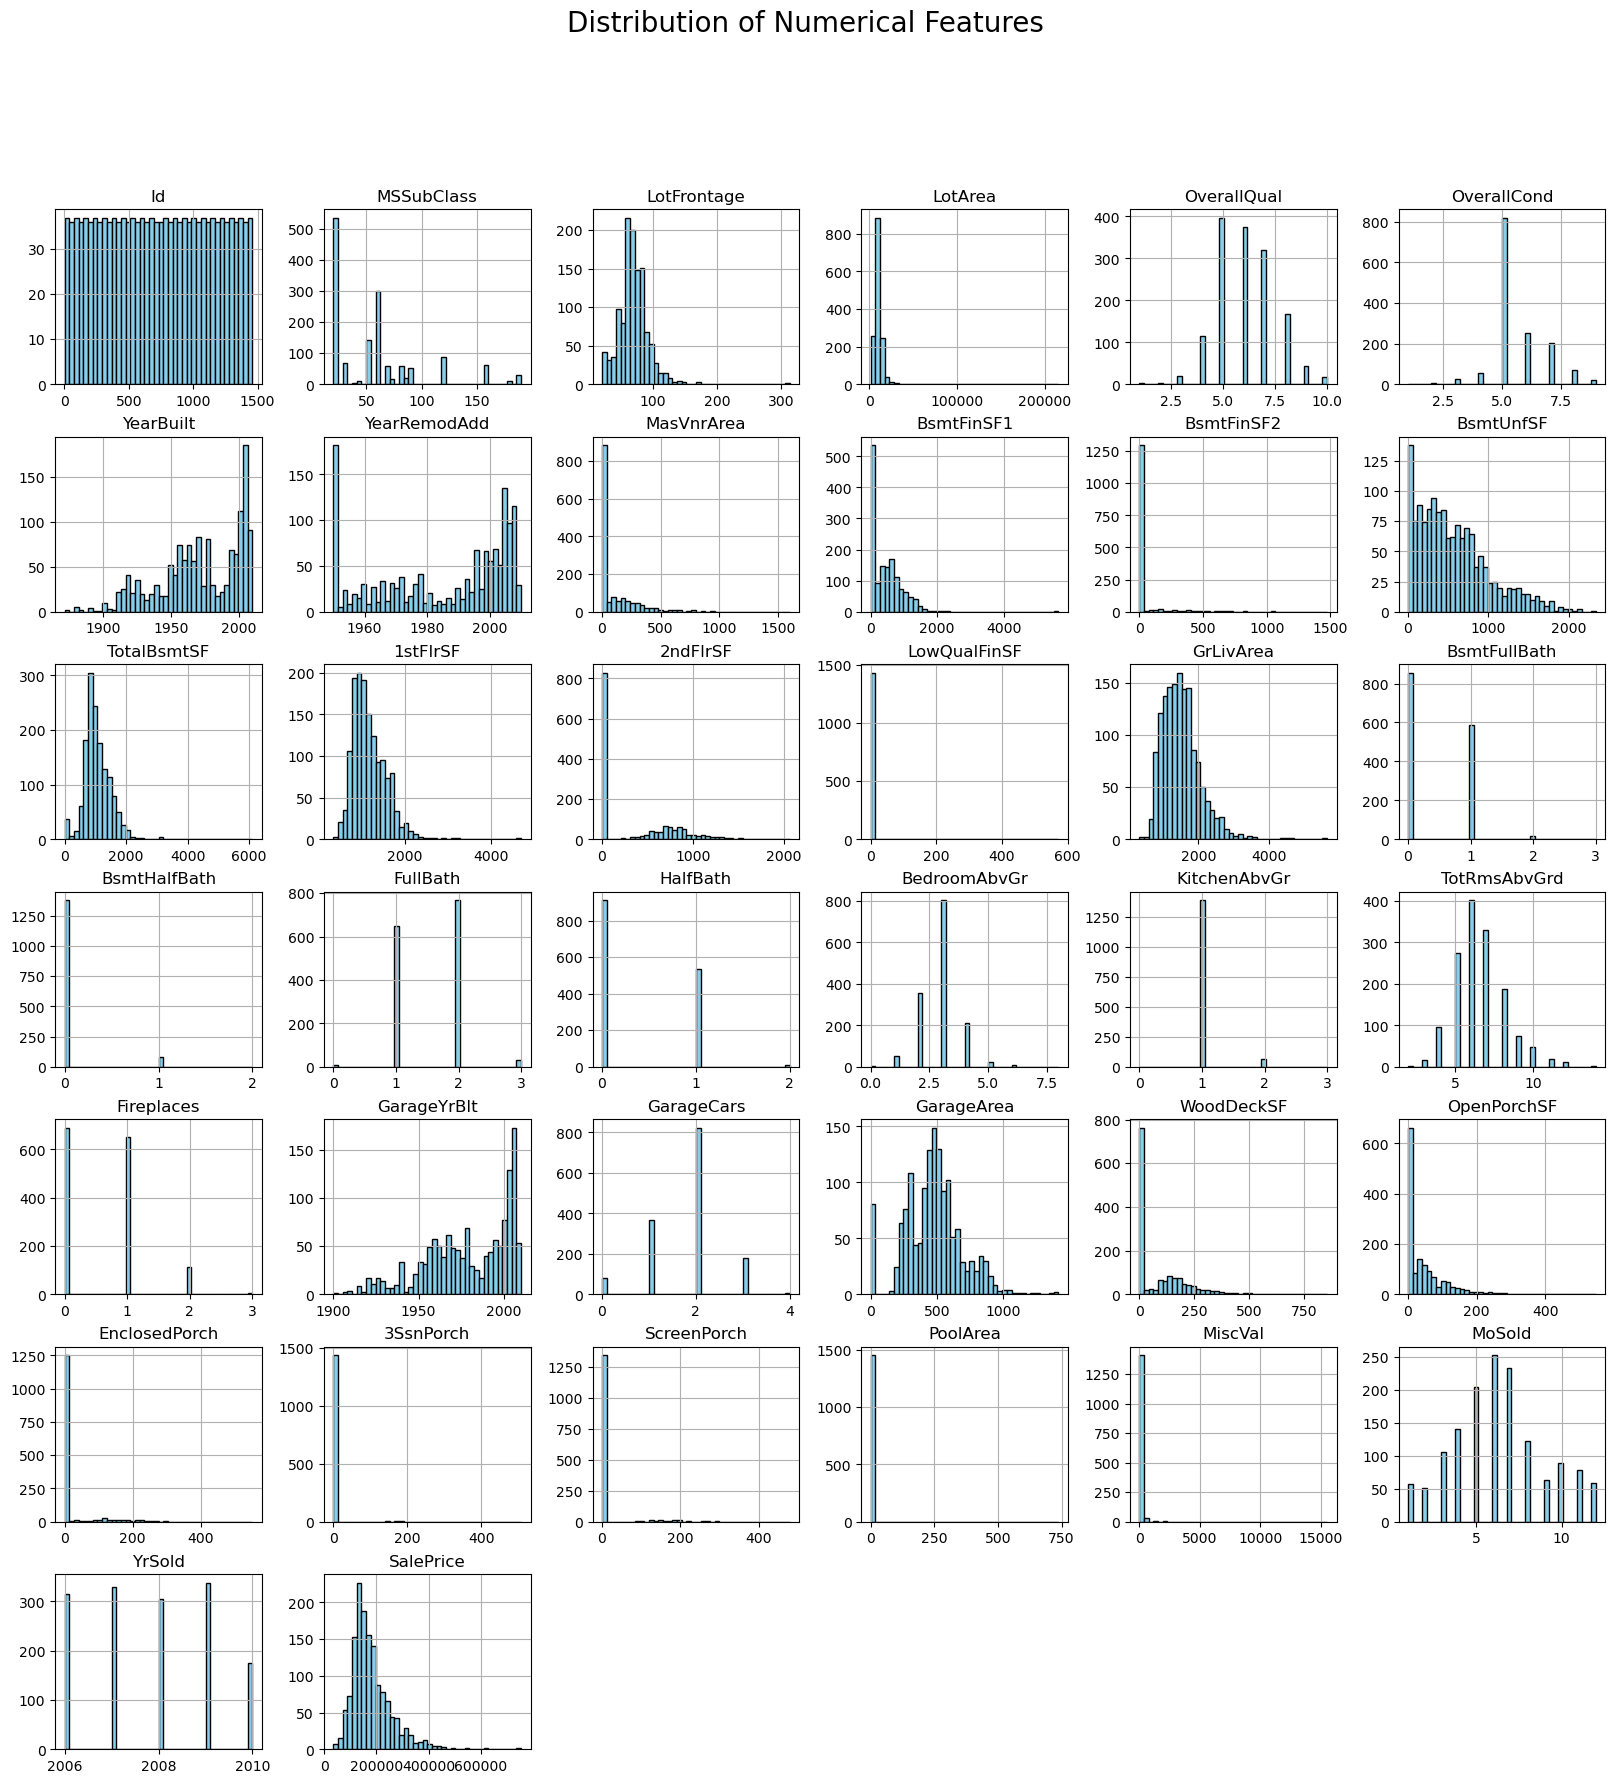

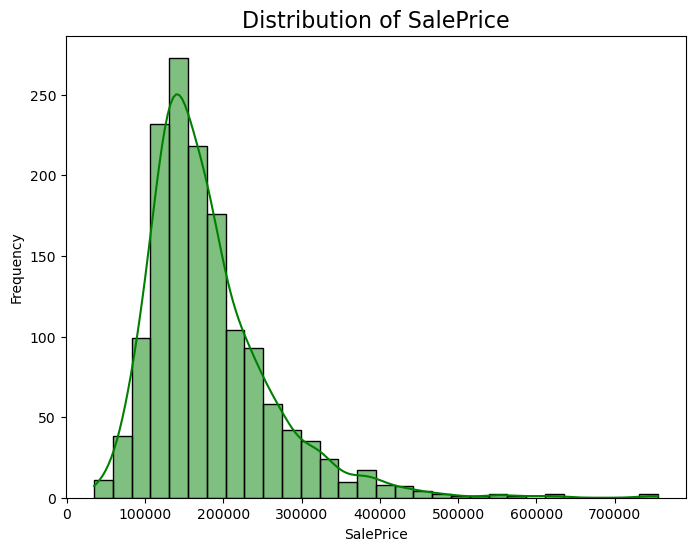

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plotting histograms for all numerical features
housing_data.hist(bins=40, figsize=(20, 20), color='skyblue', edgecolor='black')
plt.suptitle('Distribution of Numerical Features', fontsize=20)
plt.show()

# Plotting histogram for the target variable
plt.figure(figsize=(8, 6))
sns.histplot(housing_data[target_variable], bins=30, kde=True, color='green')
plt.title(f'Distribution of {target_variable}', fontsize=16)
plt.xlabel(target_variable)
plt.ylabel('Frequency')
plt.show()

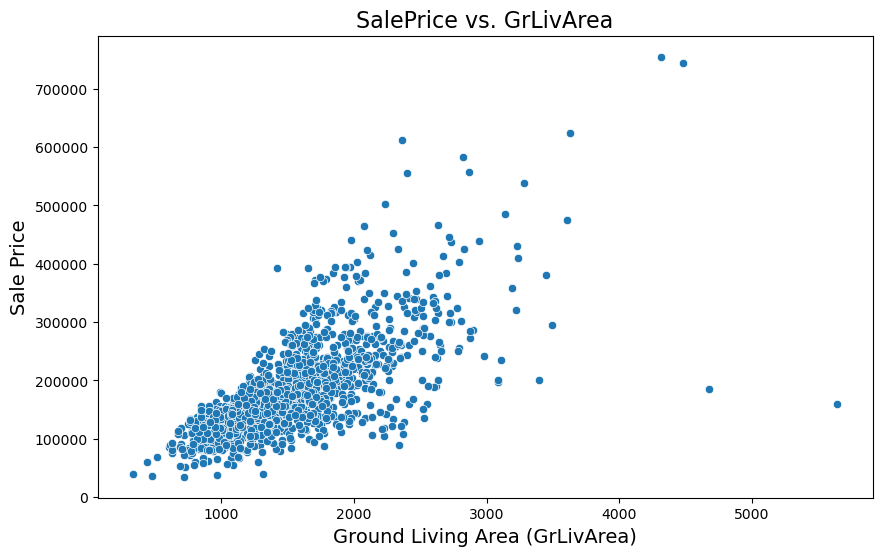

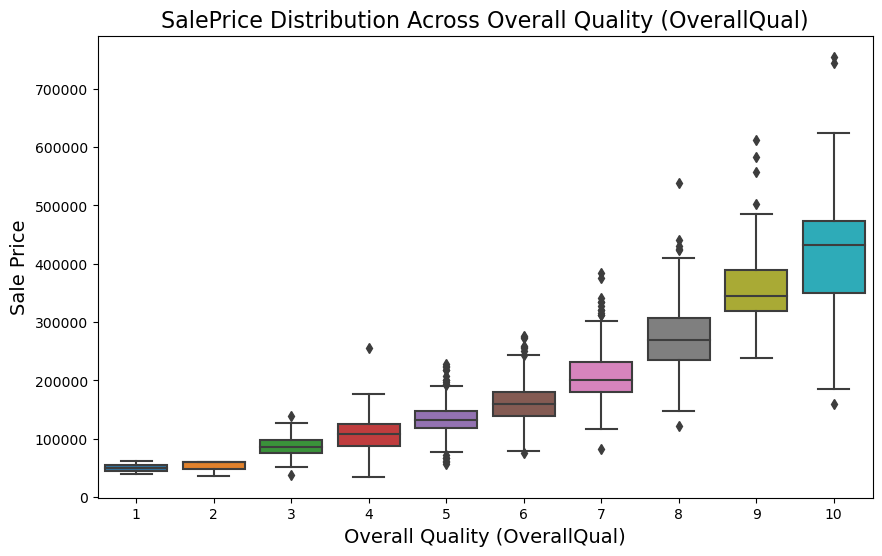

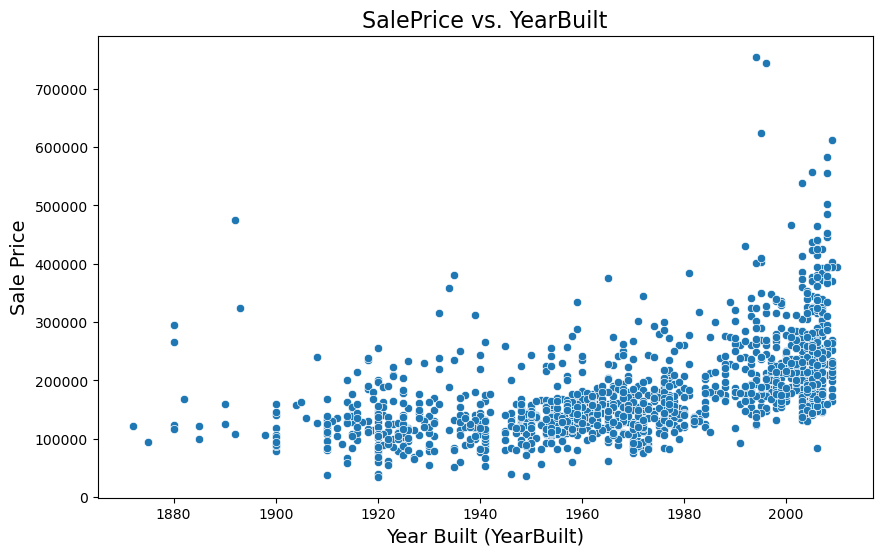

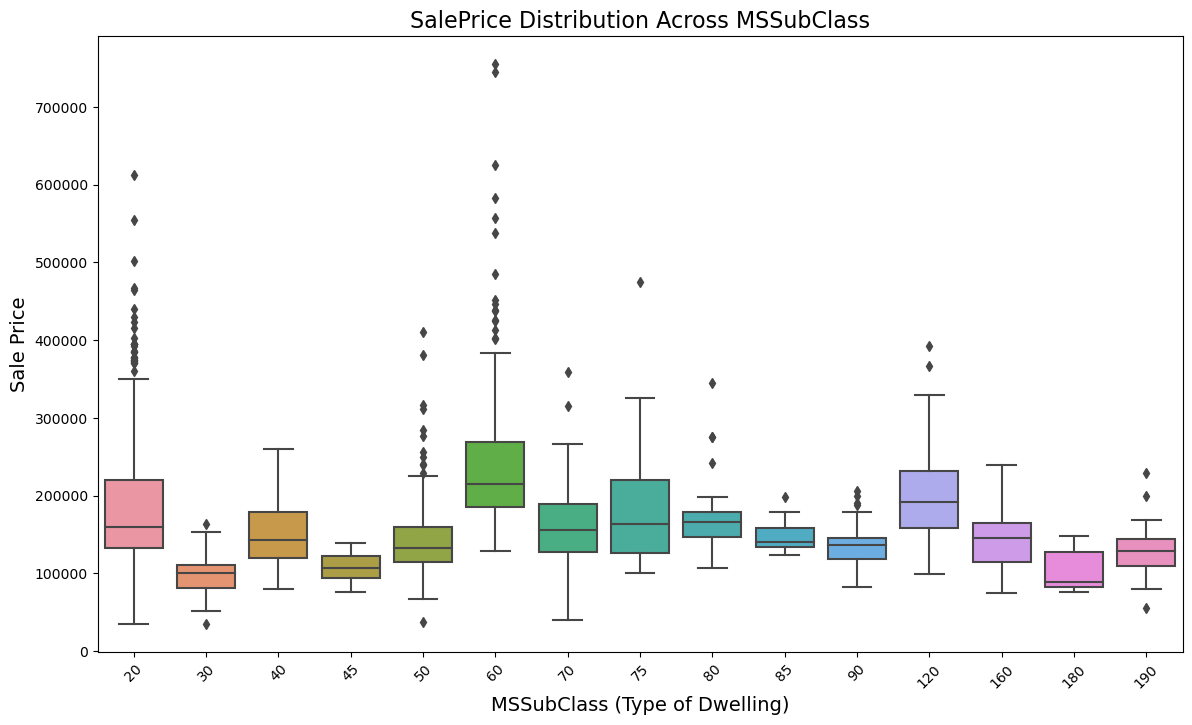

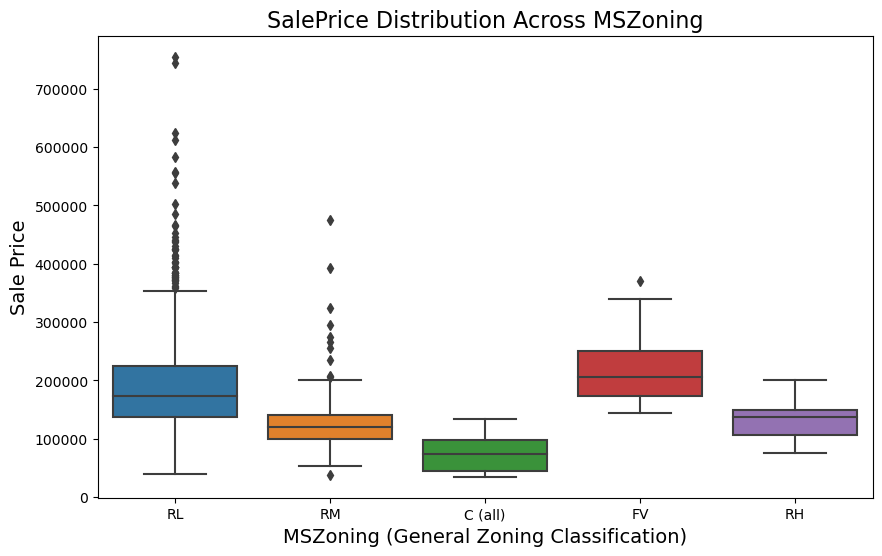

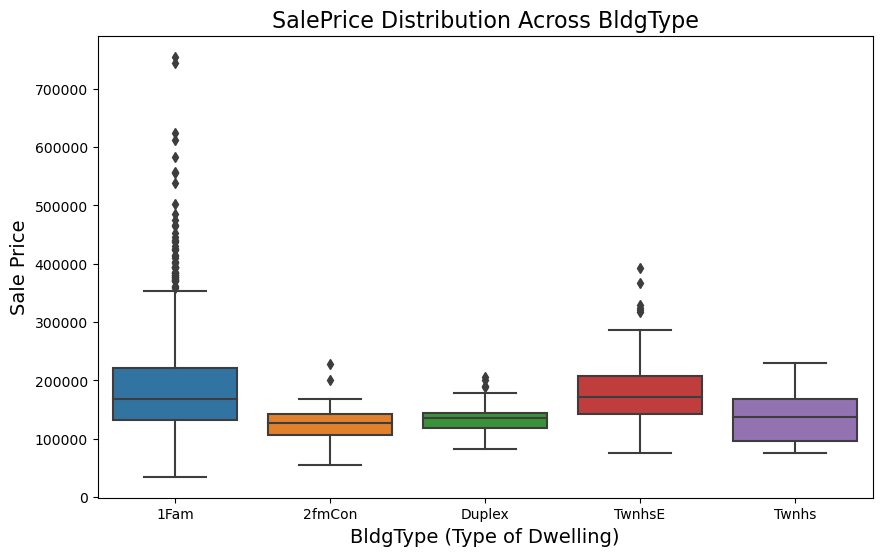

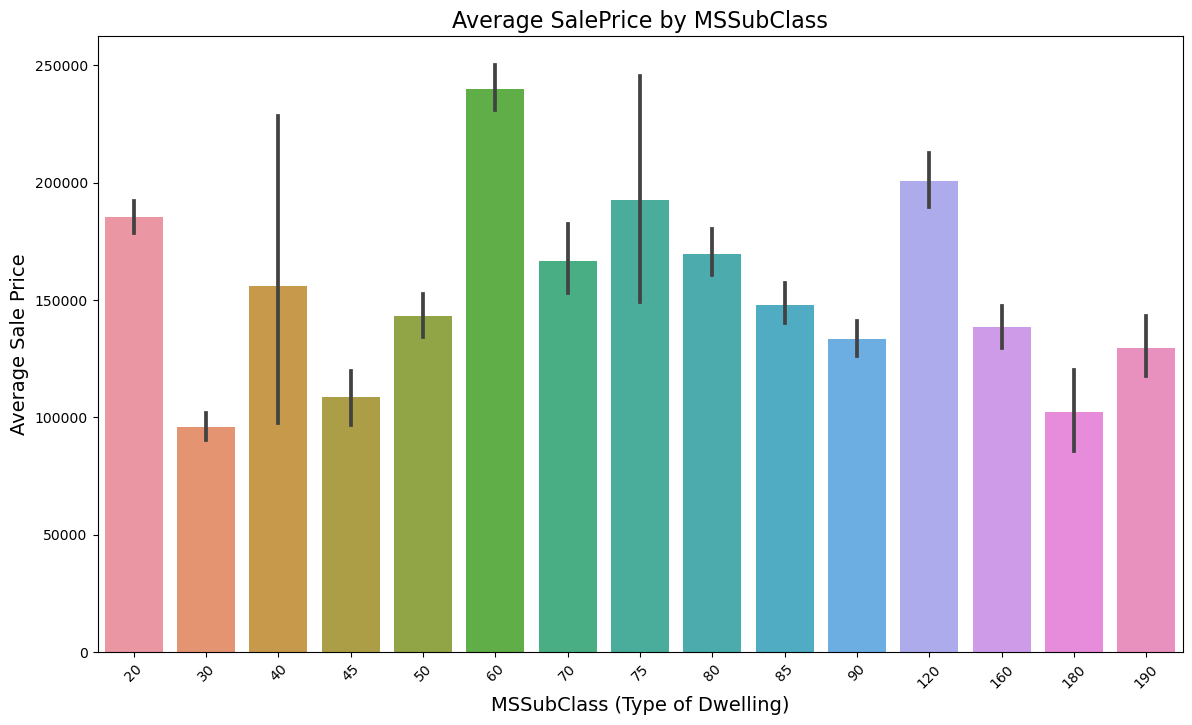

In [8]:
# Scatter plot between 'GrLivArea' (Ground living area) and 'SalePrice'
plt.figure(figsize=(10, 6))
sns.scatterplot(x='GrLivArea', y='SalePrice', data=housing_data)
plt.title('SalePrice vs. GrLivArea', fontsize=16)
plt.xlabel('Ground Living Area (GrLivArea)', fontsize=14)
plt.ylabel('Sale Price', fontsize=14)
plt.show()

# Box plot of 'OverallQual'(Rates the overall material and finish of the house) vs 'SalePrice'
plt.figure(figsize=(10, 6))
sns.boxplot(x='OverallQual', y='SalePrice', data=housing_data)
plt.title('SalePrice Distribution Across Overall Quality (OverallQual)', fontsize=16)
plt.xlabel('Overall Quality (OverallQual)', fontsize=14)
plt.ylabel('Sale Price', fontsize=14)
plt.show()

# Scatter plot between 'YearBuilt' (Year the house was built) and 'SalePrice'
plt.figure(figsize=(10, 6))
sns.scatterplot(x='YearBuilt', y='SalePrice', data=housing_data)
plt.title('SalePrice vs. YearBuilt', fontsize=16)
plt.xlabel('Year Built (YearBuilt)', fontsize=14)
plt.ylabel('Sale Price', fontsize=14)
plt.show()

# Box plot between 'MSSubclass'(Type of dwelling) and 'SalePrice'
plt.figure(figsize=(14, 8))
sns.boxplot(x='MSSubClass', y='SalePrice', data=housing_data)
plt.title('SalePrice Distribution Across MSSubClass', fontsize=16)
plt.xlabel('MSSubClass (Type of Dwelling)', fontsize=14)
plt.ylabel('Sale Price', fontsize=14)
plt.xticks(rotation=45)
plt.show()

# Box plot between 'MSZoning'(Zoning Classification) and 'SalePrice'
plt.figure(figsize=(10, 6))
sns.boxplot(x='MSZoning', y='SalePrice', data=housing_data)
plt.title('SalePrice Distribution Across MSZoning', fontsize=16)
plt.xlabel('MSZoning (General Zoning Classification)', fontsize=14)
plt.ylabel('Sale Price', fontsize=14)
plt.show()

# Box plot between 'BldgType'(Building Type) and 'SalePrice'
plt.figure(figsize=(10, 6))
sns.boxplot(x='BldgType', y='SalePrice', data=housing_data)
plt.title('SalePrice Distribution Across BldgType', fontsize=16)
plt.xlabel('BldgType (Type of Dwelling)', fontsize=14)
plt.ylabel('Sale Price', fontsize=14)
plt.show()

# Bar plot between 'MSSubclass'(Type of dwelling) and Average 'SalePrice'
plt.figure(figsize=(14, 8))
sns.barplot(x='MSSubClass', y='SalePrice', data=housing_data, estimator=lambda x: x.mean())
plt.title('Average SalePrice by MSSubClass', fontsize=16)
plt.xlabel('MSSubClass (Type of Dwelling)', fontsize=14)
plt.ylabel('Average Sale Price', fontsize=14)
plt.xticks(rotation=45)
plt.show()

### Summary of Findings

**SalePrice across OverallQual**

- Median sale price rises with every quality level. Houses rated 1 sell for far less than houses rated 10.
- The jump between levels gets larger at the top, and the boxes barely overlap between low and high ratings. Quality separates prices well.
- The spread widens with quality. The box for quality 10 is much taller than the boxes for quality 1 to 3.
- Most outliers are expensive houses at the upper end. The two highest sales, above $700,000, are rated 10, and one rated-10 house sold for only about $160,000.

**SalePrice vs YearBuilt**

- Houses built before 1980 sit mostly in a flat band between $50,000 and $250,000, with no strong trend.
- A few older houses sold far above that band, including one built around 1892 for roughly $475,000.
- From about 1990 onward, both prices and spread increase.
All the highest sales (above $600,000) were built in the 1990s or later.

**SalePrice across MSSubClass**

- Median price differs by dwelling type. Code 60 is highest, followed by 120 and 20. Codes 180, 30 and 45 are lowest.
- Codes 60 and 20 have many high outliers. The two most expensive sales in the data belong to code 60.
- Codes 45, 85 and 90 have narrow boxes, so their prices are tightly grouped.

**SalePrice across MSZoning**

- FV has the highest median, followed by RL, RH and RM. C (all) is clearly lowest.
- RL has the widest range and most of the high outliers.
- C (all) and RH have small boxes, so these groups probably contain few houses.

**SalePrice across BldgType**

- Medians are close across building types. TwnhsE and 1Fam are slightly higher, while Duplex, Twnhs and 2fmCon are lower.
- 1Fam has the widest range and nearly all the extreme outliers. The other types stay below $400,000.
- Because medians differ little and ranges overlap, building type separates price less than overall quality does.

**Average SalePrice by MSSubClass**

- Code 60 has the highest average (about $240,000), and code 30 has the lowest (below $100,000).
- Codes 40 and 75 have very long error bars, so their averages are the least reliable.
- Codes 60, 20 and 30 have short error bars, so their averages are more reliable.

**SalePrice vs GrLivArea** 

- There is a clear positive trend: larger living area goes with higher price.
- The spread widens as area grows. At 1,000 sq ft prices cluster tightly, while at 2,000 sq ft they range from about $100,000 to over $400,000.
- A few houses do not follow the trend. Of the four houses above 4,000 sq ft, two sold for above $700,000, and the other two sold below $200,000.

### Identifying and handling outliers
- **Identifying outliers**: The Interquartile Range (IQR) method is used to detect outliers in `SalePrice` (the target) and `GrLivArea`, the continuous numerical feature with the clearest relationship to price from the plots above. The scatter plot of `GrLivArea` against `SalePrice` already showed a few houses far from the main trend. `OverallQual` also showed a strong relationship with price, but it is a 1 to 10 rating, so the IQR rule is not applied to it.

- **Handling outliers**: Depending on the nature of the outliers, the options include removing them, capping them (i.e., replacing extreme values with the nearest acceptable boundary), or applying other techniques.

### Identify Outliers Using the Interquartile Range (IQR) Method
The IQR method is a common approach to detecting outliers. A value counts as an outlier if it falls below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR, where Q1 and Q3 are the first and third quartiles, respectively.

In [9]:
# Defining a function to calculate outliers based on IQR
def detect_outliers_iqr(housing_data, column):
    Q1 = housing_data[column].quantile(0.25)
    Q3 = housing_data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Identifying outliers
    outliers = housing_data[(housing_data[column] < lower_bound) | (housing_data[column] > upper_bound)]
    
    print(f"Number of outliers in '{column}': {outliers.shape[0]}")
    return outliers

# Detecting outliers in 'SalePrice' and 'GrLivArea'
saleprice_outliers = detect_outliers_iqr(housing_data, 'SalePrice')
grlivarea_outliers = detect_outliers_iqr(housing_data, 'GrLivArea')

# Checking which side of the distribution the outliers fall on and what they look like
print(f"Smallest flagged SalePrice: {saleprice_outliers['SalePrice'].min():,}")
print(f"Smallest flagged GrLivArea: {grlivarea_outliers['GrLivArea'].min():,}")
print(f"SalePrice outliers with OverallQual >= 8: {(saleprice_outliers['OverallQual'] >= 8).sum()} of {len(saleprice_outliers)}")
print("Houses with GrLivArea above 4,000 sq ft:")
display(housing_data.loc[housing_data['GrLivArea'] > 4000,
                         ['Id', 'GrLivArea', 'SalePrice', 'OverallQual', 'SaleCondition']])

Number of outliers in 'SalePrice': 61
Number of outliers in 'GrLivArea': 31
Smallest flagged SalePrice: 341,000
Smallest flagged GrLivArea: 2,775
SalePrice outliers with OverallQual >= 8: 58 of 61
Houses with GrLivArea above 4,000 sq ft:


,Id,GrLivArea,SalePrice,OverallQual,SaleCondition
523,524,4676,184750,10,Partial
691,692,4316,755000,10,Normal
1182,1183,4476,745000,10,Abnorml
1298,1299,5642,160000,10,Partial


The IQR rule flags 61 outliers in `SalePrice` and 31 in `GrLivArea`. All of them are on the high side: the smallest flagged `SalePrice` is \$341,000 and the smallest flagged `GrLivArea` is 2,775 sq ft, both far above the typical values. They look like genuine expensive and large houses rather than data errors; for example, 58 of the 61 high-priced outliers have an overall quality rating of 8 or above, so their prices are consistent with their quality.

The exceptions are the two largest houses (Id 524 and Id 1299), which sold for far less than their size and quality would suggest. Both have a `SaleCondition` of `Partial`, so their prices may not reflect the true value of the house. With only two such rows, and since the remaining outliers are real sales that the model needs to learn from, all of the outliers are kept.

### Feature Engineering

#### Age of the House
The age of the house at the time of sale can be an important predictor of its value. `HouseAge` is created as the year sold minus the year built.

In [10]:
# Creating a new feature for the age of the house at the time of sale
housing_data['HouseAge'] = housing_data['YrSold'] - housing_data['YearBuilt']
print("Created new feature 'HouseAge'.")

Created new feature 'HouseAge'.


#### Remodeled or Not
Whether the house has been remodeled can be an indicator of its condition. A house is flagged as remodeled (1) when `YearRemodAdd` differs from `YearBuilt`, and 0 otherwise.

In [11]:
# Creating a feature indicating whether the house was remodeled or not
housing_data['Remodeled'] = (housing_data['YearRemodAdd'] != housing_data['YearBuilt']).astype(int)
print("Created new feature 'Remodeled' (1 if remodeled, 0 otherwise).")

Created new feature 'Remodeled' (1 if remodeled, 0 otherwise).


#### Season of Sale
Houses sold in different seasons may have different price trends. `MoSold` is grouped into four seasons and `SeasonSold` is kept as a categorical feature. 

In [12]:
# Creating the season feature as a categorical variable.
housing_data['SeasonSold'] = housing_data['MoSold'].apply(
    lambda x: 'Spring' if x in [3, 4, 5] else
    ('Summer' if x in [6, 7, 8] else
     ('Fall' if x in [9, 10, 11] else 'Winter'))
)
print("Created categorical feature 'SeasonSold'.")


Created categorical feature 'SeasonSold'.


#### Has Pool or not
A binary feature indicating whether the house has a pool. 

In [13]:
# Creating a binary feature indicating the presence of a pool
housing_data['HasPool'] = housing_data['PoolArea'].apply(lambda x: 1 if x > 0 else 0)
print("Created feature 'HasPool'.")

Created feature 'HasPool'.


### Categorical Variables
Categorical variables stay in their original form during exploratory analysis. They are one-hot encoded inside a Scikit-learn preprocessing Pipeline after the train/test split, which means the encoder learns the categories from the training data only and can handle categories in the test data that it has not seen before. `MSSubClass` is stored as integers, but its values are dwelling-type codes with no numerical order, so it is converted to a categorical column. 

#### Converting `MSSubClass` to a categorical column

In [14]:
# MSSubClass is stored as integers, but its values are dwelling-type codes (20, 30, 60, e.t.c), so it will be converted to a categorical column.
housing_data['MSSubClass'] = housing_data['MSSubClass'].astype(str)
print(housing_data['MSSubClass'].dtype)

object


### Ordinal Variables

In [15]:
# Re-confirming that OverallQual and OverallCond are already numeric ordinal ratings.
print(housing_data[['OverallQual', 'OverallCond']].dtypes)

OverallQual    int64
OverallCond    int64
dtype: object


The `OverallQual` and `OverallCond` columns in this housing dataset are already represented as ordered numeric ratings (the output confirms that both are integer columns). They are kept as numeric features rather than passed through LabelEncoder.

### Splitting the Dataset into Training and Testing Sets
An 80/20 split is applied before fitting any preprocessing steps, which keeps information from the test set out of imputation, scaling and categorical encoding. `Id` is dropped because it is only an identifier and not a characteristic of the house. 

In [16]:
from sklearn.model_selection import train_test_split

# Separate predictors and target.
# Id is an identifier rather than a meaningful house characteristic, so exclude it.
X = housing_data.drop(columns=['SalePrice', 'Id'], errors='ignore')
y = housing_data['SalePrice']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training set size:", X_train.shape)
print("Testing set size:", X_test.shape)


Training set size: (1168, 83)
Testing set size: (292, 83)


This leaves 1,168 houses for training and 292 for testing, each with 83 predictor columns.

### Building a Leakage-Safe Preprocessing and Modelling Workflow

In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.base import clone

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Identifying column types using the training data only.
numeric_features = X_train.select_dtypes(include=['number']).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=['number']).columns.tolist()

# Numerical preprocessing: impute missing values, then standardise.
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing: fill missing values, then one-hot encode.
# In this dataset a missing category mostly means the feature is absent (no pool, no alley,
# no garage, e.t.c.), so I fill with an explicit 'None' category.
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='None')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Applying the appropriate transformations to each column group.
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ],
    remainder='drop'
)

# Defining models. Each model gets its own independent preprocessing Pipeline.
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42, n_estimators=200),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42)
}

def evaluate_pipeline(model, X_train, X_test, y_train, y_test):
    model.fit(X_train, y_train)
    train_predictions = model.predict(X_train)
    test_predictions = model.predict(X_test)

    return {
        'Train RMSE': mean_squared_error(y_train, train_predictions) ** 0.5,
        'Test RMSE': mean_squared_error(y_test, test_predictions) ** 0.5,
        'Train MAE': mean_absolute_error(y_train, train_predictions),
        'Test MAE': mean_absolute_error(y_test, test_predictions),
        'Train R²': r2_score(y_train, train_predictions),
        'Test R²': r2_score(y_test, test_predictions)
    }

# Fitting and evaluating all models through leakage-safe Pipelines.
pipelines = {
    name: Pipeline(steps=[
        ('preprocessor', clone(preprocessor)),
        ('model', clone(model))
    ])
    for name, model in models.items()
}

results = {}
for name, pipeline in pipelines.items():
    results[name] = evaluate_pipeline(
        pipeline, X_train, X_test, y_train, y_test
    )

results_df = pd.DataFrame(results).T
display(results_df.round(4))


,Train RMSE,Test RMSE,Train MAE,Test MAE,Train R²,Test R²
Linear Regression,18740.6184,70142.3485,12079.5197,21567.3077,0.9411,0.3586
Decision Tree,0.0000,43839.0529,0.0000,27141.4041,1.0000,0.7494
Random Forest,10927.9813,28896.6017,6439.1196,17643.0816,0.9800,0.8911
Gradient Boosting,13233.3034,27267.2536,9686.5431,17087.3560,0.9706,0.9031


A `ColumnTransformer` applies different preprocessing to the numerical and categorical columns:
- Numerical columns: median imputation, followed by standardisation.
- Categorical columns: missing values are filled with an explicit `'None'` category, because a missing value here usually means the house lacks that feature, followed by one-hot encoding.
- `handle_unknown='ignore'` allows the model to process categories that appear in the test data but were not present in the training data.

The preprocessor sits inside a `Pipeline` with each model. When `.fit()` is called, preprocessing is fitted only on the training data. During cross-validation, the preprocessing is refitted independently within each fold. Four models are compared: Linear Regression, Decision Tree, Random Forest (200 trees) and Gradient Boosting.

### Comparing Model Performance

All models are evaluated on the same training and testing split. Because preprocessing is part of each Pipeline, imputation, scaling and one-hot encoding are learned from the training data only.

In [18]:
# Reviewing the feature types passed to the preprocessing Pipeline.
print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("\nCategorical columns:")
print(categorical_features)


Numerical features: 38
Categorical features: 45

Categorical columns:
['MSSubClass', 'MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition', 'SeasonSold']


In [19]:
# Displaying model comparison.
display(results_df.sort_values('Test RMSE').round(4))

# Linear Regression has a much larger test error than the other models, so I check whether a few extreme predictions are responsible.
lr_pred = pd.Series(pipelines['Linear Regression'].predict(X_test), index=y_test.index)
lr_abs_err = (lr_pred - y_test).abs()
worst = lr_abs_err.idxmax()
print(f"Linear Regression median absolute test error: {lr_abs_err.median():,.0f}")
print(f"Largest miss (row {worst}): predicted {lr_pred[worst]:,.0f}, actual {y_test[worst]:,.0f}")


,Train RMSE,Test RMSE,Train MAE,Test MAE,Train R²,Test R²
Gradient Boosting,13233.3034,27267.2536,9686.5431,17087.3560,0.9706,0.9031
Random Forest,10927.9813,28896.6017,6439.1196,17643.0816,0.9800,0.8911
Decision Tree,0.0000,43839.0529,0.0000,27141.4041,1.0000,0.7494
Linear Regression,18740.6184,70142.3485,12079.5197,21567.3077,0.9411,0.3586


Linear Regression median absolute test error: 12,081
Largest miss (row 1170): predicted -927,439, actual 171,000


### Interpreting the Model Comparison

Training and test metrics are compared as follows:
- A large gap between training and test performance may indicate overfitting.
- Lower test RMSE and MAE indicate smaller prediction errors.
- A higher test R² indicates that the model explains more variation in unseen house prices.

What the results show:
- Gradient Boosting is the best model on the test set (RMSE 27,267, MAE 17,087, R² 0.9031), followed by Random Forest (RMSE 28,897, MAE 17,643, R² 0.8911).
- The Decision Tree overfits badly: it fits the training data perfectly (RMSE 0, R² 1.0), but its test RMSE is 43,839 and its test R² drops to 0.7494.
- Linear Regression has the weakest test result (RMSE 70,142, R² 0.3586) even though its training R² is 0.9411. Its typical error is not that large (the median absolute test error is about 12,081), but one test house is predicted at about -\$927,439 when it actually sold for \$171,000, and that single miss dominates the RMSE. This suggests Linear Regression is sensitive to unusual combinations of the many one-hot features, which makes it unreliable here.
- Gradient Boosting and Random Forest also show a gap between training R² (0.9706 and 0.9800) and test R² (0.9031 and 0.8911), so some overfitting remains in both.

### Hyperparameter Tuning

The model with the strongest test-set performance is selected for further tuning. Gradient Boosting has the lowest test RMSE and MAE and the highest test R², so it is the one tuned.

#### Hyperparameter Tuning with GridSearchCV

The preprocessing Pipeline is included in GridSearchCV. This is important: during each cross-validation fold, the imputer, scaler and encoder are fitted only on that fold's training portion, which prevents preprocessing leakage between folds. 

In [20]:
from sklearn.model_selection import GridSearchCV

# Tuning the Gradient Boosting model inside the complete preprocessing Pipeline.
gbr_pipeline = Pipeline(steps=[
    ('preprocessor', clone(preprocessor)),
    ('model', GradientBoostingRegressor(random_state=42))
])

param_grid = {
    'model__n_estimators': [100, 200],
    'model__learning_rate': [0.05, 0.1],
    'model__max_depth': [2, 3],
    'model__min_samples_split': [2, 5],
    'model__min_samples_leaf': [1, 2]
}

grid_search = GridSearchCV(
    estimator=gbr_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best hyperparameters:")
print(grid_search.best_params_)
print(f"Best cross-validation RMSE: {(-grid_search.best_score_) ** 0.5:.4f}")


Fitting 5 folds for each of 32 candidates, totalling 160 fits
Best hyperparameters:
{'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__min_samples_leaf': 2, 'model__min_samples_split': 2, 'model__n_estimators': 200}
Best cross-validation RMSE: 27857.0891


The grid has 32 combinations (number of trees, learning rate, tree depth, minimum samples to split and minimum samples per leaf), each evaluated with 5-fold cross-validation, which gives 160 fits. The best combination uses 200 trees, a learning rate of 0.1, a maximum depth of 3, `min_samples_split` of 2 and `min_samples_leaf` of 2, with a cross-validated RMSE of about 27,857. The best number of trees, learning rate and depth are all the largest values in the grid, so a wider grid might find a slightly better model.

After hyperparameter tuning, the best complete Pipeline is evaluated once on the held-out test set. The hyperparameter search itself used only the training data (through cross-validation); the test set was used only for the earlier model comparison and for this evaluation. 

In [21]:
# Retrieving the best complete preprocessing + modelling Pipeline.
best_gbr = grid_search.best_estimator_

tuned_train_predictions = best_gbr.predict(X_train)
tuned_test_predictions = best_gbr.predict(X_test)

best_gbr_metrics = {
    'Train RMSE': mean_squared_error(y_train, tuned_train_predictions) ** 0.5,
    'Test RMSE': mean_squared_error(y_test, tuned_test_predictions) ** 0.5,
    'Train MAE': mean_absolute_error(y_train, tuned_train_predictions),
    'Test MAE': mean_absolute_error(y_test, tuned_test_predictions),
    'Train R²': r2_score(y_train, tuned_train_predictions),
    'Test R²': r2_score(y_test, tuned_test_predictions)
}

print("Tuned Gradient Boosting Pipeline performance:")
display(pd.Series(best_gbr_metrics).to_frame('Value').round(4))


Tuned Gradient Boosting Pipeline performance:


,Value
Train RMSE,10230.2928
Test RMSE,27230.9429
Train MAE,7570.3176
Test MAE,16701.9581
Train R²,0.9825
Test R²,0.9033


The tuned model reaches a test RMSE of 27,231, MAE of 16,702 and R² of 0.9033. That is almost the same as the default Gradient Boosting model (RMSE 27,267, MAE 17,087, R² 0.9031), so tuning gave only a very small improvement. Its training R² (0.9825) is still well above its test R², so some overfitting remains. The cross-validated RMSE (about 27,857) is close to the test RMSE, which suggests the test result is not just a lucky split.

### Final Evaluation on the Held-Out Test Set

In [22]:
final_y_pred = best_gbr.predict(X_test)

final_rmse = mean_squared_error(y_test, final_y_pred) ** 0.5
final_mae = mean_absolute_error(y_test, final_y_pred)
final_r2 = r2_score(y_test, final_y_pred)

print("Final test-set performance:")
print(f"RMSE: {final_rmse:,.2f}")
print(f"MAE:  {final_mae:,.2f}")
print(f"R²:   {final_r2:.4f}")


Final test-set performance:
RMSE: 27,230.94
MAE:  16,701.96
R²:   0.9033


The following metrics report performance on the test set, which was not used to fit the preprocessing steps or to tune the hyperparameters (it was used earlier only to compare the models). The tuned model has a test RMSE of 27,230.94, an MAE of 16,701.96 and an R² of 0.9033.

- **RMSE (27,230.94):** the typical size of the prediction error in dollars, with large errors weighted more heavily.
- **MAE (16,701.96):** the average absolute error. In practical terms, predictions are off by about \$16,700 on average, which is roughly 10% of the median sale price (\$163,000).
- **R² (0.9033):** the model explains about 90.3% of the variation in the sale prices of unseen houses.

The RMSE is well above the MAE, which suggests that a small number of large misses add a lot to the error. The training R² (0.9825) is well above the test R², so some overfitting remains. The test scores are also almost the same as those of the default Gradient Boosting model, so tuning added very little.

# REPORT

The tuned Gradient Boosting Pipeline was evaluated on a held-out test set of 292 houses. It explains about 90.3% of the variation in sale prices (R² of 0.9033), with an RMSE of about \$27,231 and an MAE of about \$16,702. It was the most accurate of the models tried, ahead of Random Forest (R² 0.8911), the Decision Tree (0.7494) and Linear Regression (0.3586). These scores come from a leakage-safe Pipeline, so imputation, scaling and encoding were learned from the training data only.

### Key Points:

#### 1. Model Performance
- RMSE measures the typical prediction error while penalising larger errors more heavily. The test RMSE is about \$27,231. Because it is well above the MAE, it suggests that a small number of large misses on expensive houses add a lot to the error.
- MAE measures the average absolute difference between predicted and actual sale prices. The test MAE is about \$16,702.
- R² measures the proportion of variation in sale prices explained by the model on the test set. The test R² is 0.9033, so the model explains about 90.3% of the variation in the prices of unseen houses.

The training R² is 0.9825, so there is still a gap between training and test performance, which means the model is somewhat overfitted to the training data.

#### 2. Feature Importance
For the tree-based Gradient Boosting model, feature importance scores help identify which transformed input features contributed most to the model. The feature names are retrieved from the fitted preprocessing Pipeline. 

### Critical Features:

1. Feature Importance Plot

Number of transformed features: 322
         Feature  Importance
num__OverallQual      0.4965
  num__GrLivArea      0.1569
 num__GarageCars      0.0385
 num__BsmtFinSF1      0.0375
num__TotalBsmtSF      0.0330
   num__1stFlrSF      0.0284
   num__2ndFlrSF      0.0257
    num__LotArea      0.0179
cat__BsmtQual_Ex      0.0162
  num__YearBuilt      0.0122
Top 2 share of total importance:  0.653
Top 10 share of total importance: 0.863


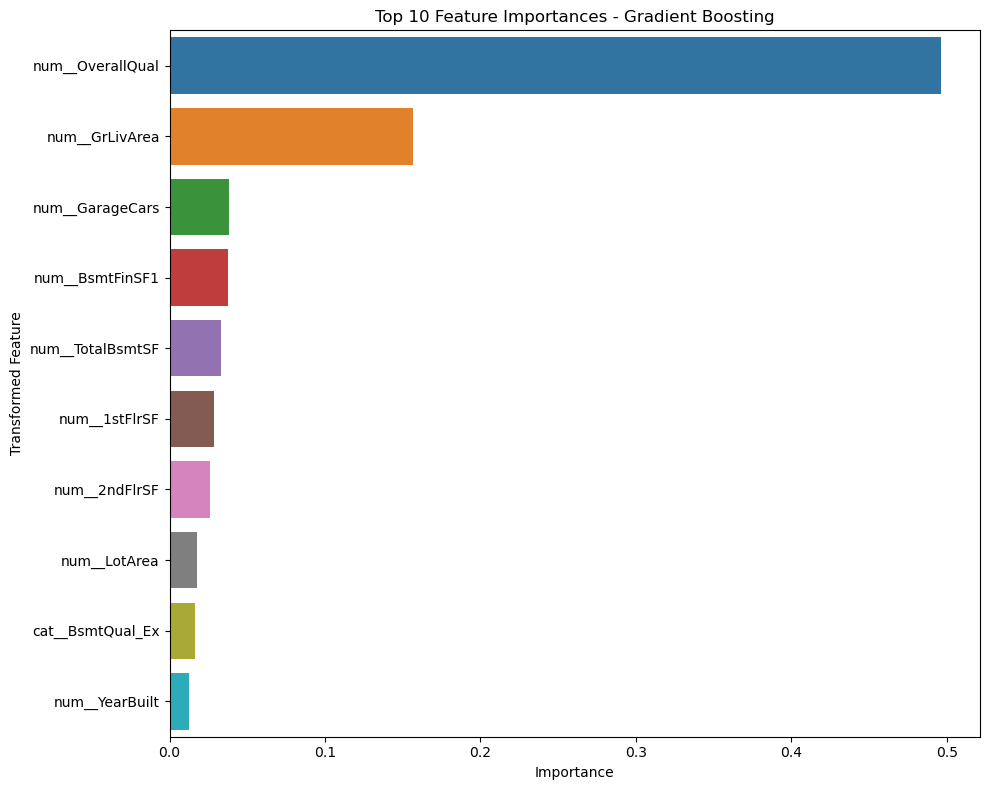

In [25]:
# Extracting feature names from the fitted preprocessing stage.
fitted_preprocessor = best_gbr.named_steps['preprocessor']
feature_names = fitted_preprocessor.get_feature_names_out()

feature_importances = best_gbr.named_steps['model'].feature_importances_

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_importances
}).sort_values('Importance', ascending=False)

top_features = importance_df.head(10)

print(f"Number of transformed features: {len(feature_names)}")
print(top_features.round(4).to_string(index=False))
print(f"Top 2 share of total importance:  {importance_df['Importance'].head(2).sum():.3f}")
print(f"Top 10 share of total importance: {top_features['Importance'].sum():.3f}")

plt.figure(figsize=(10, 8))
sns.barplot(data=top_features, x='Importance', y='Feature')
plt.title('Top 10 Feature Importances - Gradient Boosting')
plt.xlabel('Importance')
plt.ylabel('Transformed Feature')
plt.tight_layout()
plt.show()


`OverallQual` is by far the most important feature (about 0.50 of the total importance), followed by `GrLivArea` (about 0.16); together they account for roughly 65% of the total. The next most important features are `GarageCars`, `BsmtFinSF1`, `TotalBsmtSF`, `1stFlrSF`, `2ndFlrSF` and `LotArea`, each contributing less than 0.04, followed by excellent basement quality (`BsmtQual_Ex`) and `YearBuilt`. The top 10 features account for about 86% of the total importance, and none of the engineered features (`HouseAge`, `Remodeled`, `SeasonSold`, `HasPool`) appear among them.

### Partial Dependence Plots (PDPs)
Partial dependence plots show how the model's predicted sale price changes as a selected numerical feature varies, averaging over the other features. The plots cover the typical range of each feature (the 5th to 95th percentile), not the extremes. The original, untransformed training data is passed to the complete Pipeline, with the numeric columns converted to floats because scikit-learn requires this for partial dependence plots, so the preprocessing steps are applied consistently.

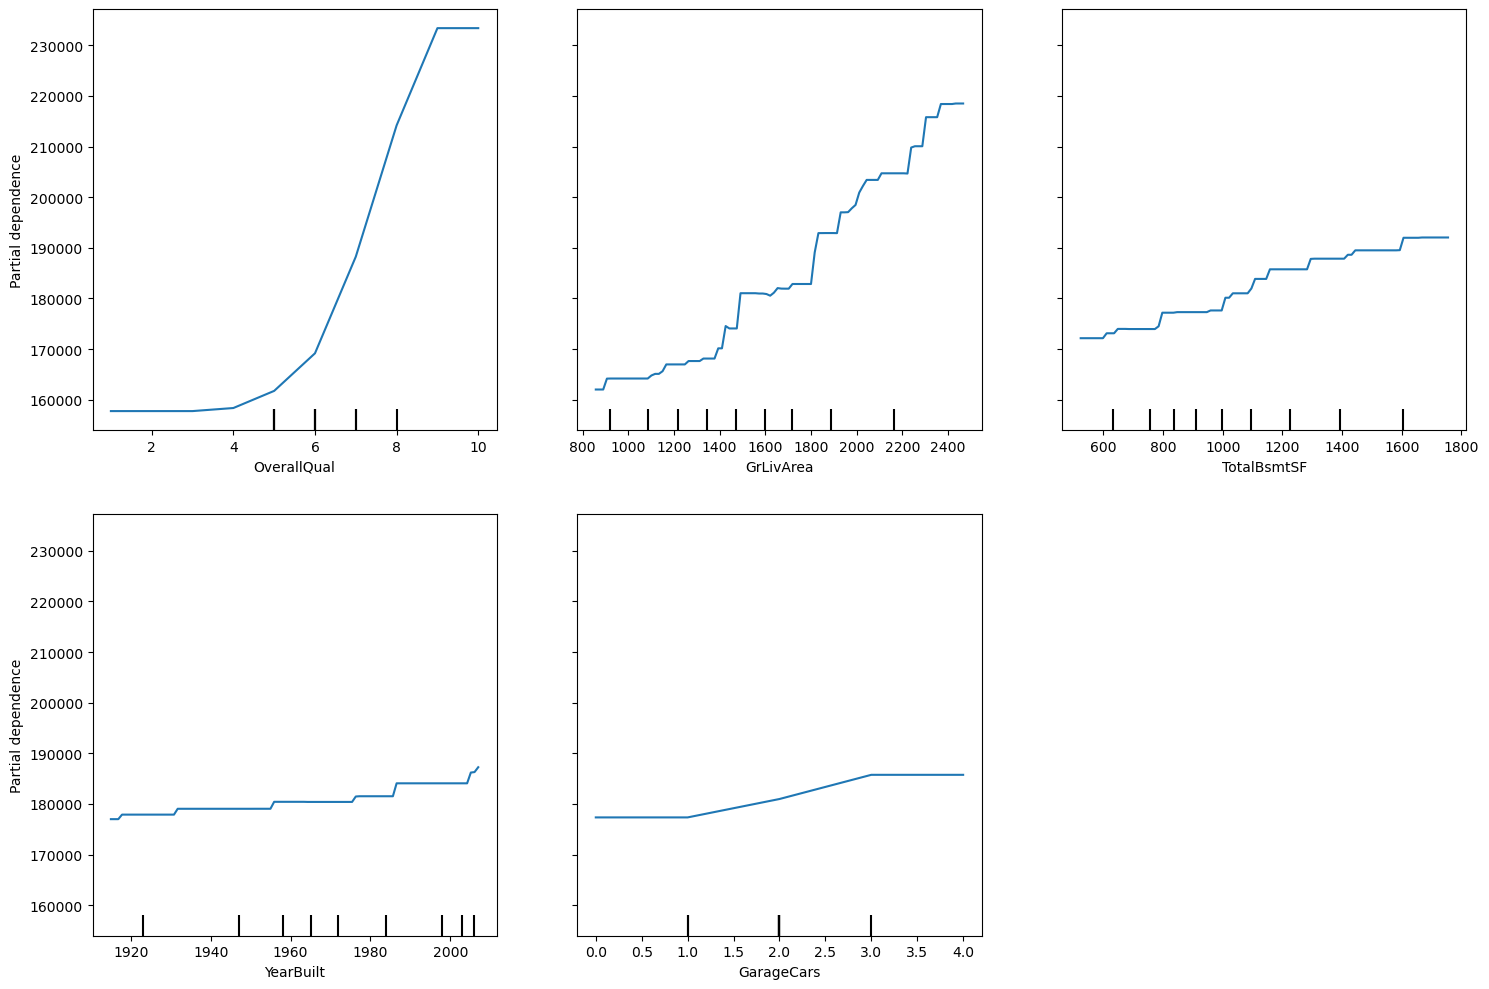

In [24]:
from sklearn.inspection import PartialDependenceDisplay

features_to_plot = ['OverallQual', 'GrLivArea', 'TotalBsmtSF', 'YearBuilt', 'GarageCars']

# Partial dependence requires floating-point numeric columns, so I convert them on a copy.
X_train_pdp = X_train.copy()
X_train_pdp[numeric_features] = X_train_pdp[numeric_features].astype(float)

fig, ax = plt.subplots(figsize=(15, 10))
PartialDependenceDisplay.from_estimator(
    best_gbr,
    X_train_pdp,
    features_to_plot,
    ax=ax
)
plt.tight_layout()
plt.show()


#### OverallQual
- The plot shows a strong positive relationship between OverallQual and the predicted sale price.
- The predicted price is flat at about \$158,000 for ratings up to 4, then rises steeply from about \$162,000 at rating 5 to about \$233,000 at rating 9, and levels off between ratings 9 and 10.
- The overall swing of roughly \$75,000 is the largest of the five features, which shows that overall quality is the most influential factor in the model's price predictions.

#### GrLivArea
- There's a clear positive relationship between GrLivArea and the predicted price.
- The predicted price rises from about \$162,000 at around 900 sq ft to about \$218,000 at around 2,450 sq ft, a swing of roughly \$56,000, in step-like increments because the model is built from trees.
- This suggests that the size of the living area is a significant factor in house prices.

#### TotalBsmtSF
- Similar to GrLivArea, there's a positive relationship, but a much weaker one: the predicted price rises from about \$172,000 to about \$192,000 across the plotted range, a swing of roughly \$20,000.
- This implies that basement size matters but has a much smaller effect on price than the living area.

#### YearBuilt
- The effect of YearBuilt is small and fairly flat: the predicted price rises only from about \$177,000 for the oldest houses to about \$187,000 for the newest, in small steps.
- This is much weaker than the pattern in the raw scatter plot, probably because quality, size and the other features already capture much of what the year built tells the model.

#### GarageCars
- There's a positive relationship: the predicted price rises from about \$177,000 for 0 or 1 cars to about \$186,000 for 3 cars, and stays flat beyond that.
- The effect (roughly \$9,000) is much smaller than for OverallQual and GrLivArea.

#### Identifying Critical Features

Based on the feature importance scores and the PDPs, the following features appear to be most critical in predicting house prices:

- OverallQual: By far the strongest impact on the predicted value (about half of the total importance and the largest PDP swing).
- GrLivArea: The living area is the second most influential factor (about 16% of the importance and a PDP swing of about \$56,000).
- Basement, garage and floor-area features (`TotalBsmtSF`, `BsmtFinSF1`, `GarageCars`, `1stFlrSF`, `2ndFlrSF`): These come next in the importance ranking, but each contributes less than 4% of the importance, and the PDPs for `TotalBsmtSF` and `GarageCars` show swings of only about \$20,000 and \$9,000.
